# Урок 5. Деревья решений и случайный лес

Логистическая регрессия считает **баллы**. Дерево задаёт **вопросы «да/нет»** по очереди.
Случайный лес — сотни деревьев, которые **голосуют**.

## 0. Данные и подготовка (как в уроке 4)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

df = pd.read_csv("../data/titanic.csv")
y = df["Survived"]

df["Title"] = (df["Name"].str.split(", ").str[1]
                          .str.split(" ").str[0]
                          .str.rstrip("."))
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df["Title"] = df["Title"].where(df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

num_cols = ["Pclass", "Age", "Fare", "FamilySize"]
cat_cols = ["Sex", "Embarked", "Title"]

# Дереву масштаб не нужен, поэтому StandardScaler убран. One-hot остаётся.
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore")), cat_cols),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## 1. Маленькое дерево: 2 вопроса

In [2]:
tree = make_pipeline(preprocess, DecisionTreeClassifier(max_depth=2, random_state=42))
tree.fit(df, y)

# имена колонок без приставок «num__» и «cat__»
names = [n.split("__")[1] for n in tree[0].get_feature_names_out()]

# weights = [погибли, выжили] в каждом листе
print(export_text(tree[-1], feature_names=names, show_weights=True))

|--- Title_Mr <= 0.50
|   |--- FamilySize <= 4.50
|   |   |--- weights: [72.00, 251.00] class: 1
|   |--- FamilySize >  4.50
|   |   |--- weights: [41.00, 10.00] class: 0
|--- Title_Mr >  0.50
|   |--- Fare <= 26.27
|   |   |--- weights: [351.00, 39.00] class: 0
|   |--- Fare >  26.27
|   |   |--- weights: [85.00, 42.00] class: 0



**Вывод:** первый вопрос дерево выбрало само: «титул Mr или нет».
Женщины и мальчики из маленьких семей (≤ 4) → выжил (251 из 323). Большие семьи → погиб даже среди женщин и детей.
Взрослые мужчины → погиб при любой цене билета.

## 2. Переобучение: дерево без ограничений

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df, y, test_size=0.2, random_state=42, stratify=y
)

big_tree = make_pipeline(preprocess, DecisionTreeClassifier(random_state=42))
big_tree.fit(X_train, y_train)

print(f"учёба:   {big_tree.score(X_train, y_train):.3f}")
print(f"экзамен: {big_tree.score(X_test, y_test):.3f}")
print(f"глубина: {big_tree[-1].get_depth()}, листьев: {big_tree[-1].get_n_leaves()}")

учёба:   0.985
экзамен: 0.810
глубина: 19, листьев: 165


**Вывод:** на учёбе 98.5%, на экзамене 81%. Дерево задало 19 вопросов подряд и не нашло правило, а **зазубрило** учебных людей.
Признак переобучения — большой разрыв между train и test.

## 3. Какая глубина лучше

In [4]:
rows = []
for depth in [1, 2, 3, 4, 5, 6, 8, 10, None]:          # None = без ограничения
    model = make_pipeline(preprocess, DecisionTreeClassifier(max_depth=depth, random_state=42))
    r = cross_validate(model, df, y, cv=cv, scoring="accuracy", return_train_score=True)
    rows.append({"глубина": depth,
                 "train": r["train_score"].mean(),
                 "cv": r["test_score"].mean()})

depths = pd.DataFrame(rows)
depths.round(3)

,глубина,train,cv
0,1.0,0.786,0.777
1,2.0,0.801,0.778
2,3.0,0.834,0.826
3,4.0,0.845,0.827
4,5.0,0.855,0.826
5,6.0,0.870,0.820
6,8.0,0.903,0.823
7,10.0,0.931,0.819
8,NaN,0.983,0.800


**Вывод:** train растёт всегда (дерево лучше запоминает).
CV растёт до глубины 4 (0.777 → 0.827), потом почти не меняется (0.819–0.826), а без ограничений падает до 0.800.
Глубина 1–2 — недообучение (слишком просто). Дальше растёт **разрыв** между train и cv: 0.018 при глубине 4, 0.112 при глубине 10. Это переобучение.
Лучшая глубина 3–4: CV ≈ 0.827.

## 4. Случайный лес

300 деревьев, каждое учится на немного разных данных. Итог — голосование.
`min_samples_leaf=5` — в каждом листе минимум 5 человек: нельзя строить правило под одного пассажира.

In [5]:
models = {
    "Логистическая регрессия": make_pipeline(preprocess, LogisticRegression(max_iter=2000)),
    "Дерево, глубина 4":       make_pipeline(preprocess, DecisionTreeClassifier(max_depth=4, random_state=42)),
    "Лес без ограничений":     make_pipeline(preprocess, RandomForestClassifier(n_estimators=300, random_state=42)),
    "Лес, min_samples_leaf=5": make_pipeline(preprocess, RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                                                 random_state=42)),
}

rows = []
for name, model in models.items():
    r = cross_validate(model, df, y, cv=cv, scoring=["accuracy", "roc_auc"], return_train_score=True)
    rows.append({"модель": name,
                 "train": r["train_accuracy"].mean(),
                 "cv": r["test_accuracy"].mean(),
                 "std": r["test_accuracy"].std(),
                 "AUC": r["test_roc_auc"].mean()})

pd.DataFrame(rows).round(3)

,модель,train,cv,std,AUC
0,Логистическая регрессия,0.830,0.829,0.009,0.873
1,"Дерево, глубина 4",0.845,0.827,0.017,0.851
2,Лес без ограничений,0.983,0.814,0.023,0.874
3,"Лес, min_samples_leaf=5",0.863,0.841,0.009,0.882


**Вывод:** лес без ограничений тоже переобучился (train 0.98). Лес с `min_samples_leaf=5` — лучшая модель курса: CV ≈ 0.84, AUC ≈ 0.88.

## 5. Важность признаков для леса

In [6]:
forest = models["Лес, min_samples_leaf=5"]
forest.fit(df, y)

# насколько каждый признак помогал деревьям делить людей (в сумме = 1)
pd.Series(forest[-1].feature_importances_, index=names).sort_values(ascending=False).round(3)

Title_Mr        0.170
Fare            0.155
Sex_female      0.142
Sex_male        0.138
Pclass          0.108
Age             0.089
FamilySize      0.068
Title_Mrs       0.043
Title_Miss      0.035
Title_Master    0.016
Embarked_S      0.013
Embarked_C      0.012
Embarked_Q      0.006
Title_Rare      0.005

**Вывод:** самые важные — титул Mr (0.170), цена (0.155), пол (0.142 + 0.138: это две колонки одного признака, вместе 0.28) и класс (0.108). Порт почти не важен. Совпадает с EDA.
Важность показывает **насколько** признак полезен, но не **в какую сторону** (помогает выжить или мешает).
Осторожно: у `Fare` и `Age` много разных значений, и деревья таким признакам обычно завышают важность.

---
# 🏠 Домашка

Решай в ячейках ниже. Под каждым заданием — код и вывод словами.

## Задание 1. Дерево глубины 3 картинкой

Нарисуй дерево и найди лист, где больше всего выживших. Опиши путь от корня: кто эти люди?

Подсказка:
```python
tree3 = make_pipeline(preprocess, DecisionTreeClassifier(max_depth=3, random_state=42))
tree3.fit(df, y)
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(tree3[-1], feature_names=names, class_names=["Погиб", "Выжил"],
          filled=True, ax=ax, fontsize=9)
plt.show()
```

|--- Title_Mr <= 0.50
|   |--- FamilySize <= 4.50
|   |   |--- Fare <= 18.38
|   |   |   |--- weights: [54.00, 96.00] class: 1
|   |   |--- Fare >  18.38
|   |   |   |--- weights: [18.00, 155.00] class: 1
|   |--- FamilySize >  4.50
|   |   |--- Pclass <= 2.50
|   |   |   |--- weights: [0.00, 6.00] class: 1
|   |   |--- Pclass >  2.50
|   |   |   |--- weights: [41.00, 4.00] class: 0
|--- Title_Mr >  0.50
|   |--- Fare <= 26.27
|   |   |--- Age <= 32.50
|   |   |   |--- weights: [258.00, 33.00] class: 0
|   |   |--- Age >  32.50
|   |   |   |--- weights: [93.00, 6.00] class: 0
|   |--- Fare >  26.27
|   |   |--- Fare <= 26.77
|   |   |   |--- weights: [5.00, 11.00] class: 1
|   |   |--- Fare >  26.77
|   |   |   |--- weights: [80.00, 31.00] class: 0



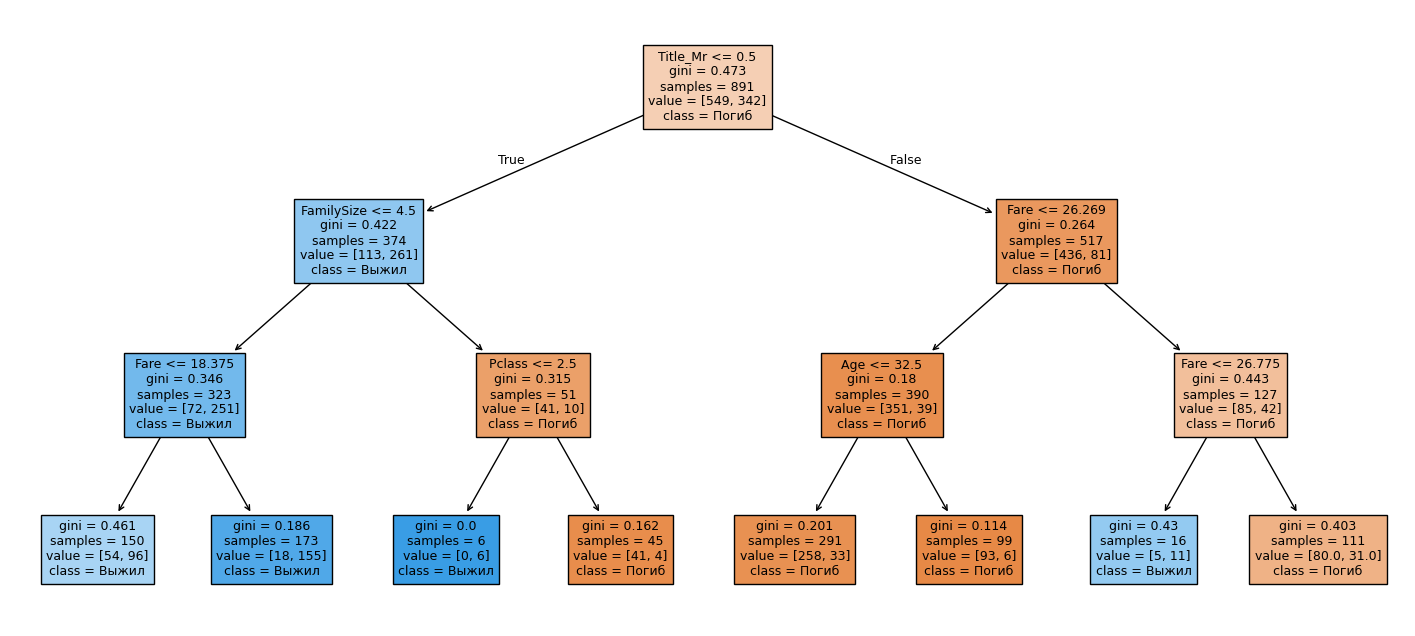

In [7]:
# df, y, preprocess уже подготовлены в части 0
tree3 = make_pipeline(preprocess, DecisionTreeClassifier(max_depth=3, random_state=42))
tree3.fit(df, y)

names = [n.split("__")[1] for n in tree3[0].get_feature_names_out()]
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(tree3[-1], feature_names=names, class_names=["Погиб", "Выжил"],
          filled=True, ax=ax, fontsize=9)
plt.show()
print(export_text(tree3[-1], feature_names=names, show_weights=True))

### Мой ответ на задание 1

Всего 891 пассажир, 342 выжили.

**Как читать лист:** `weights: [погибли, выжили]`. Первое число — погибшие, второе — выжившие. Всего людей в листе = сумма двух чисел.

**Лист, где выжило больше всего людей: `[18, 155]`.**

Путь от корня:
1. `Title_Mr <= 0.50` → **не Mr** (женщины и мальчики).
2. `FamilySize <= 4.50` → семья **до 4 человек**.
3. `Fare > 18.38` → билет **дороже 18.38**.

В листе 173 человека: 18 погибли, 155 выжили. Доля выживших: 155 / 173 = **0.90**.

**Все 8 листьев:**

| Кто | Погибли | Выжили | Всего | Доля выживших |
|---|---|---|---|---|
| не Mr, семья ≤ 4, билет ≤ 18.38 | 54 | 96 | 150 | 0.64 |
| **не Mr, семья ≤ 4, билет > 18.38** | 18 | 155 | 173 | **0.90** |
| не Mr, семья > 4, класс 1–2 | 0 | 6 | 6 | 1.00 |
| не Mr, семья > 4, класс 3 | 41 | 4 | 45 | 0.09 |
| Mr, билет ≤ 26.27, возраст ≤ 32.5 | 258 | 33 | 291 | 0.11 |
| Mr, билет ≤ 26.27, возраст > 32.5 | 93 | 6 | 99 | 0.06 |
| Mr, билет 26.27–26.77 | 5 | 11 | 16 | 0.69 |
| Mr, билет > 26.77 | 80 | 31 | 111 | 0.28 |

**Вывод:** больше всего выжили женщины и мальчики (не Mr) из небольших семей с дорогим билетом: 155 из 173 (90%).

Лист `[0, 6]` имеет 100%, но в нём всего 6 человек. Ему мало доверия.

Это **связь, а не причина**. Дерево не доказывает, что дорогой билет спас людей. Цена билета обычно связана с классом, и дерево использует её как подсказку.

## Задание 2. График глубины

Две линии (train и cv) от глубины. Строку с `None` убери. Отметь лучшую глубину через `ax.axvline`.
Таблица `depths` уже посчитана в части 3.

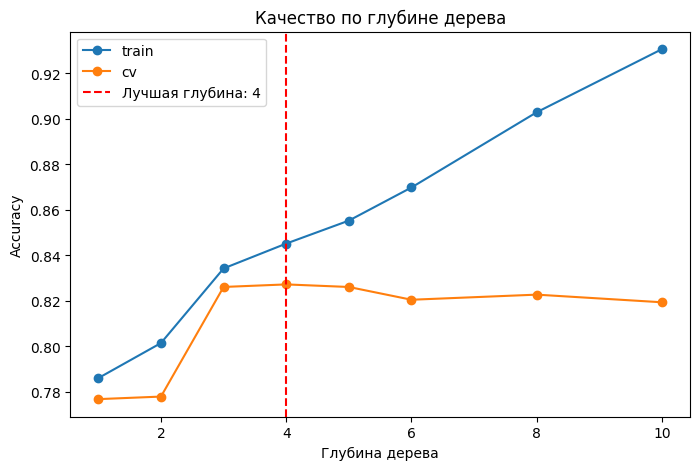

In [8]:
plot_depths = depths.dropna(subset=["глубина"])
best_depth = plot_depths.loc[plot_depths["cv"].idxmax(), "глубина"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(plot_depths["глубина"], plot_depths["train"], marker="o", label="train")
ax.plot(plot_depths["глубина"], plot_depths["cv"], marker="o", label="cv")
ax.axvline(best_depth, color="red", linestyle="--",
           label=f"Лучшая глубина: {int(best_depth)}")
ax.set(xlabel="Глубина дерева", ylabel="Accuracy",
       title="Качество по глубине дерева")
ax.legend()
plt.show()

**Вывод:**
- **train** растёт всё время (0.786 → 0.931): чем глубже дерево, тем лучше оно запоминает учебных людей.
- **cv** растёт до глубины 4 (0.777 → 0.827), потом почти стоит на месте (0.819–0.826). Он не падает заметно: разница 0.008 меньше разброса между частями.
- Растёт **разрыв** между линиями: 0.018 при глубине 4 и 0.112 при глубине 10. Это переобучение: дерево зубрит, а на новых людях лучше не становится.
- Лучшая глубина **3–4**: у 3 и 4 cv почти одинаковый (0.826 и 0.827), разница — шум. Глубины 1–2 — недообучение.

## Задание 3. Лес: min_samples_leaf = 1, 2, 5, 10, 20

Таблица: train, cv, разница train − cv. Какое значение лучше? Что происходит с разницей, когда `min_samples_leaf` растёт?

In [9]:
# df, y, preprocess, cv, cross_validate уже есть из части 0
rows = []
for leaf_size in [1, 2, 5, 10, 20]:
    forest_leaf = make_pipeline(preprocess,
                                RandomForestClassifier(n_estimators=300,
                                                       min_samples_leaf=leaf_size,
                                                       random_state=42))
    r = cross_validate(forest_leaf, df, y, cv=cv, scoring="accuracy",
                       return_train_score=True)
    train_score = r["train_score"].mean()
    cv_score = r["test_score"].mean()
    rows.append({"min_samples_leaf": leaf_size,
                 "train": train_score,
                 "cv": cv_score,
                 "разница": train_score - cv_score})

leaf_results = pd.DataFrame(rows)
best_leaf = leaf_results.loc[leaf_results["cv"].idxmax(), "min_samples_leaf"]
print(leaf_results.round(3).to_string(index=False))
print(f"Лучшее значение min_samples_leaf: {int(best_leaf)}")

 min_samples_leaf  train    cv  разница
                1  0.983 0.814    0.170
                2  0.907 0.844    0.063
                5  0.863 0.841    0.022
               10  0.846 0.832    0.015
               20  0.814 0.800    0.014
Лучшее значение min_samples_leaf: 2


**Вывод:**

| min_samples_leaf | train | cv | разница |
|---|---|---|---|
| 1 | 0.983 | 0.814 | 0.170 |
| 2 | 0.907 | 0.844 | 0.063 |
| 5 | 0.863 | 0.841 | 0.022 |
| 10 | 0.846 | 0.832 | 0.015 |
| 20 | 0.814 | 0.800 | 0.014 |

- **Лучший cv у `min_samples_leaf = 2`** (0.844). Код так и выбрал.
- Но у значения 5 cv почти такой же (0.841). Разница 0.003 меньше разброса между фолдами (в уроках 2 и 4 он был 0.009–0.015), поэтому это шум.
- Я выбираю **5**: разрыв train − cv у него намного меньше (0.022 против 0.063). Лес меньше зубрит.
- Когда `min_samples_leaf` растёт, разница **падает**: в каждом листе должно быть больше людей, поэтому лес не может запомнить отдельных пассажиров.
- Но маленькая разница ≠ лучшая модель. При 20 разница самая маленькая (0.014), а cv самый плохой (0.800). Модель стала слишком простой (недообучение).

## Задание 4. Вопрос без кода

Друг говорит: «Моё дерево угадывает 98.5% — лучшая модель!» Что ты у него спросишь первым делом и почему?

**Ответ:** Первым делом спрошу: «На каких людях ты считал эти 98.5%?»

Если на тех же, на которых дерево училось (train), то число ничего не значит. Дерево могло просто **зазубрить** этих людей. В нашем уроке так и было: на учёбе 98.5%, на экзамене только 81%.

Честная оценка считается на **новых** людях: на тесте или в кросс-валидации. Поэтому вторым вопросом спрошу: «Какая точность на тесте или в кросс-валидации?» Если она сильно ниже, дерево переобучено.